# GreenCampus AI – AI-Based Anomaly Detection

## 1. Introduction

This notebook uses Artificial Intelligence to identify unusual
campus resource-consumption patterns.

Isolation Forest is used as the anomaly detection algorithm.

The model analyzes occupancy, electricity, water, waste, and
temperature to classify observations as Normal or Anomaly.

#### Loading the cleaned data

In [2]:
import pandas as pd
import numpy as nd
import matplotlib.pyplot as plt

df = pd.read_csv("cleaned_campus_sustainability_data.csv")

df["Date"] = pd.to_datetime(df["Date"])

print("Dataset shape:", df.shape)

df.head

Dataset shape: (1825, 10)


<bound method NDFrame.head of            Date Building Building_Type  Occupancy  Electricity_kWh  \
0    2025-07-01  Block A      Academic        444          1437.09   
1    2025-07-01  Block B      Academic        269          1091.78   
2    2025-07-01  Block C    Laboratory        186           707.71   
3    2025-07-01  Library       Library        230           760.70   
4    2025-07-01   Hostel        Hostel        555          1679.32   
...         ...      ...           ...        ...              ...   
1820 2026-06-30  Block A      Academic        418          1344.65   
1821 2026-06-30  Block B      Academic        365          1014.04   
1822 2026-06-30  Block C    Laboratory        189           687.59   
1823 2026-06-30  Library       Library        249           754.50   
1824 2026-06-30   Hostel        Hostel        486          1739.88   

      Water_Litres  Waste_kg  Temperature_C Working_Day Event_Day  
0          8384.17     47.61           28.0         Yes      

## 2. Features Used for Anomaly Detection

In [3]:
features = ["Occupancy", "Electricity_kWh", "Water_Litres", "Waste_kg", "Temperature_C"]

X = df[features]

X.head()

,Occupancy,Electricity_kWh,Water_Litres,Waste_kg,Temperature_C
0,444,1437.09,8384.17,47.61,28.0
1,269,1091.78,4583.04,23.77,28.0
2,186,707.71,3556.96,22.42,28.0
3,230,760.70,4039.62,24.38,28.0
4,555,1679.32,9611.07,54.21,28.0


#### Install/import the AI model

In [4]:
from sklearn.ensemble import IsolationForest

## 3. Isolation Forest Model

In [5]:
model = IsolationForest(contamination = 0.03, random_state = 42)

model.fit(X)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.03
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


## 4. Detecting Anomalies

In [6]:
df["Anomaly_Prediction"] = model.predict(X)

In [7]:
df["Anomaly"] = df["Anomaly_Prediction"].map({ 1: "Normal", -1: "Anomaly"})

In [8]:
df["Anomaly"].value_counts()

Anomaly
Normal     1770
Anomaly      55
Name: count, dtype: int64

## 5. Anomaly Score Analysis

In [9]:
df["Anomaly_Score"] = model.decision_function(X)

In [10]:
most_unusual = df.sort_values("Anomaly_Score").head(20)

most_unusual[["Date", "Building", "Occupancy", "Electricity_kWh","Water_Litres" , "Waste_kg", "Anomaly_Score", "Anomaly"]]

,Date,Building,Occupancy,Electricity_kWh,Water_Litres,Waste_kg,Anomaly_Score,Anomaly
139,2025-07-28,Hostel,630,1913.80,11594.64,83.73,-0.135699,Anomaly
1329,2026-03-23,Hostel,664,1938.98,11186.41,80.38,-0.135269,Anomaly
1399,2026-04-06,Hostel,650,1770.28,11640.46,81.96,-0.133003,Anomaly
209,2025-08-11,Hostel,634,1908.54,11637.67,81.96,-0.131525,Anomaly
469,2025-10-02,Hostel,616,1861.41,11478.75,75.76,-0.119762,Anomaly
1139,2026-02-13,Hostel,595,1793.37,10893.69,73.52,-0.112866,Anomaly
1104,2026-02-06,Hostel,600,1659.26,10454.09,73.42,-0.107630,Anomaly
879,2025-12-23,Hostel,568,1640.79,10144.44,76.13,-0.105563,Anomaly
1100,2026-02-06,Block A,564,1495.26,10769.96,72.96,-0.105162,Anomaly
1379,2026-04-02,Hostel,553,2118.16,10068.28,64.54,-0.103645,Anomaly


#### Checking our intentional anomalies

In [11]:
test_cases = df[((df["Date"] == "2026-02-15") & (df["Building"] == "Block A")) | ((df["Date"] == "2026-04-10") & (df["Building"] == "Block B")) | ((df["Date"] == "2026-05-20") & (df["Building"] == "Library"))]

test_cases[["Date", "Building", "Electricity_kWh", "Water_Litres", "Waste_kg", "Anomaly_Score", "Anomaly"]]

,Date,Building,Electricity_kWh,Water_Litres,Waste_kg,Anomaly_Score,Anomaly
1145,2026-02-15,Block A,1584.73,553.61,6.95,0.008131,Normal
1416,2026-04-10,Block B,1171.87,12456.55,27.65,0.015589,Normal
1618,2026-05-20,Library,1094.30,4833.74,74.97,-0.021946,Anomaly


## 6. Visualization of Detected Anomalies

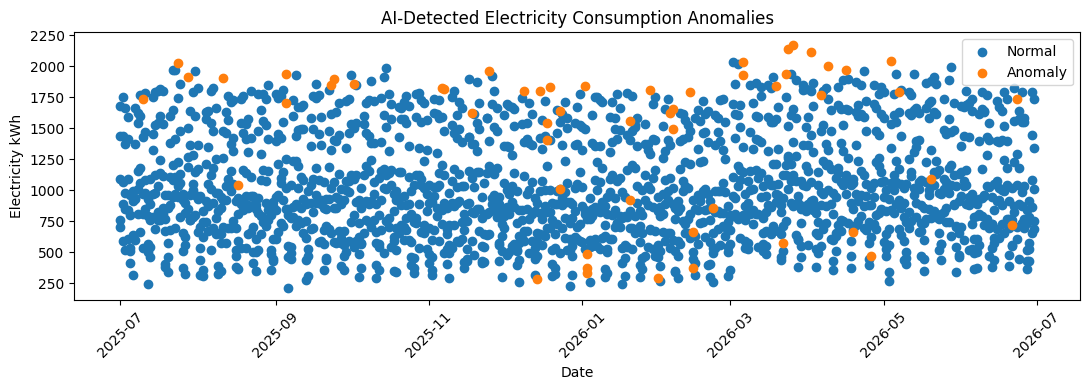

In [12]:
plt.figure(figsize=(11,4))

normal = df[df["Anomaly"] == "Normal"]
anomaly = df[df["Anomaly"] == "Anomaly"]

plt.scatter(normal["Date"], normal["Electricity_kWh"], label="Normal")

plt.scatter(anomaly["Date"], anomaly["Electricity_kWh"], label="Anomaly")

plt.title("AI-Detected Electricity Consumption Anomalies")
plt.xlabel("Date")
plt.ylabel("Electricity kWh")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 7. Anomalies by Building

In [13]:
building_anomalies = (df[df["Anomaly"] == "Anomaly"].groupby("Building").size().sort_values(ascending=False))
building_anomalies

Building
Hostel     37
Block C     6
Block A     5
Block B     4
Library     3
dtype: int64

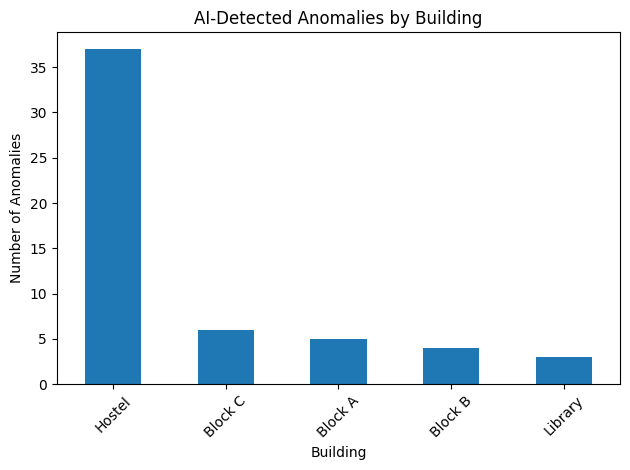

In [14]:
building_anomalies.plot(kind="bar")

plt.title("AI-Detected Anomalies by Building")
plt.xlabel("Building")
plt.ylabel("Number of Anomalies")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Create an AI insight

In [15]:
def generate_insight(row):
    if row["Anomaly"] == "Normal":
        return "Resource consumption appears within the detected normal pattern."

    insights = []

    if row["Electricity_kWh"] > df["Electricity_kWh"].quantile(0.95):
        insights.append("Unusually high electricity consumption")

    if row["Water_Litres"] > df["Water_Litres"].quantile(0.95):
        insights.append("Unusually high water consumption")

    if row["Waste_kg"] > df["Waste_kg"].quantile(0.95):
        insights.append("Unusually high waste generation")

    if not insights:
        return "Unusual overall resource-consumption pattern detected."

    return "Potential issue: " + ", ".join(insights) + ". Investigation is recommended."

In [16]:
df["AI_Insight"] = df.apply(generate_insight, axis = 1)

In [17]:
df[df["Anomaly"] == "Anomaly"][["Date", "Building", "Anomaly_Score", "AI_Insight"]].head(20)

,Date,Building,Anomaly_Score,AI_Insight
49,2025-07-10,Hostel,-0.033374,Potential issue: Unusually high water consumpt...
119,2025-07-24,Hostel,-0.018242,Potential issue: Unusually high electricity co...
139,2025-07-28,Hostel,-0.135699,Potential issue: Unusually high electricity co...
209,2025-08-11,Hostel,-0.131525,Potential issue: Unusually high electricity co...
239,2025-08-17,Hostel,-0.009046,Unusual overall resource-consumption pattern d...
330,2025-09-05,Block A,-0.047071,Potential issue: Unusually high water consumpt...
334,2025-09-05,Hostel,-0.072398,Potential issue: Unusually high electricity co...
424,2025-09-23,Hostel,-0.056068,Potential issue: Unusually high electricity co...
429,2025-09-24,Hostel,-0.046937,Potential issue: Unusually high electricity co...
469,2025-10-02,Hostel,-0.119762,Potential issue: Unusually high electricity co...


#### Save the AI results

In [18]:
df.to_csv("C:/Users/Urja Chauhan/PycharmProjects/PythonProject/campus_sustainability_ai_results.csv", index = False)

print("AI results saved successfully!")

AI results saved successfully!


#### Creating a simple AI Evaluation

In [19]:
total_anomalies = (df["Anomaly"] == "Anomaly").sum()

total_records = len(df)

anomaly_percentage = (total_anomalies/total_records) * 100

print("Total records: ", total_records)
print("Detected anomalies: ", total_anomalies)
print(("Detected anomaly percentage: ", anomaly_percentage, 2), "%")

Total records:  1825
Detected anomalies:  55
('Detected anomaly percentage: ', np.float64(3.0136986301369864), 2) %


## 8. Review of Intentional Test Cases

In [20]:
for _, row in test_cases.iterrows():

    print(row["Date"].date(), "|", row["Building"], "|", row["Anomaly"])

2026-02-15 | Block A | Normal
2026-04-10 | Block B | Normal
2026-05-20 | Library | Anomaly


## 9. AI Findings

The AI model identifies observations whose resource-consumption
patterns differ from the normal patterns in the dataset.

An anomaly indicates that further investigation may be required.
It does not automatically confirm the underlying cause.

## 10. Responsible AI Note

The anomaly results are used for decision support.
Human review is required before taking any operational action.